# Re-evaluating the Titanic model without data leakage

Added in 2026 to check the original notebook (`01_feature_engineering_random_forest.ipynb`), which reported **98.9% accuracy**. Its strongest features, *family survival rate* and *ticket survival rate*, were computed from the `Survived` column of the **whole** dataset (test passengers included) before splitting. In other words, the model was partly told the answer.

Here the same idea is kept, but those rates are computed **only from the training fold**, inside the cross-validation.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline

plt.rcParams.update({'figure.facecolor': '#09090b', 'axes.facecolor': '#09090b', 'savefig.facecolor': '#09090b',
                     'axes.edgecolor': '#27272a', 'axes.labelcolor': '#a1a1aa', 'text.color': '#e4e4e7',
                     'xtick.color': '#a1a1aa', 'ytick.color': '#71717a', 'axes.grid': True, 'grid.color': '#27272a',
                     'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('../data/titanic.csv')
y = df['Survived']
df.shape

(891, 12)

## Features that do not use the target

In [2]:
def base_features(d):
    out = pd.DataFrame(index=d.index)
    titulo = d['Name'].str.extract(r',\s*([^\.]*)\.')[0].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    out['title'] = titulo.where(titulo.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
    out['sex'] = (d['Sex'] == 'female').astype(int)
    out['pclass'] = d['Pclass']
    out['family_size'] = d['SibSp'] + d['Parch'] + 1
    out['ticket_freq'] = d.groupby('Ticket')['Ticket'].transform('count')   # counts, not outcomes: no leak
    out['fare_pp'] = d['Fare'].fillna(d['Fare'].median()) / out['ticket_freq']
    out['deck'] = d['Cabin'].str[0].fillna('M')
    out['embarked'] = d['Embarked'].fillna('S')
    out['age'] = d['Age']
    out['surname'] = d['Name'].str.split(',').str[0]
    out['ticket'] = d['Ticket']
    return out

X = base_features(df)
X.head()

,title,sex,pclass,family_size,ticket_freq,fare_pp,deck,embarked,age,surname,ticket
0,Mr,0,3,2,1,7.2500,M,S,22.0,Braund,A/5 21171
1,Mrs,1,1,2,1,71.2833,C,C,38.0,Cumings,PC 17599
2,Miss,1,3,1,1,7.9250,M,S,26.0,Heikkinen,STON/O2. 3101282
3,Mrs,1,1,2,2,26.5500,C,S,35.0,Futrelle,113803
4,Mr,0,3,1,1,8.0500,M,S,35.0,Allen,373450


## Target-based features, learned only from the training data

`GroupSurvival` learns the survival rate of each family and ticket in `fit` (training data only) and applies it in `transform`. On the training rows the rate leaves the passenger's own outcome out (leave-one-out). Unseen groups get the training mean. Age is imputed with training medians by class and sex.

In [3]:
class GroupSurvival(BaseEstimator, TransformerMixin):
    def fit(self, X, y):
        y = pd.Series(np.asarray(y), index=X.index)
        self.media_ = y.mean()
        self.familia_ = y.groupby(X['surname']).agg(['mean', 'count'])
        self.ticket_ = y.groupby(X['ticket']).agg(['mean', 'count'])
        self.edad_ = X.groupby(['pclass', 'sex'])['age'].median()
        return self

    def _tasa(self, claves, tabla, X, y_propio=None):
        stats = tabla.reindex(claves.values)
        return pd.Series(stats['mean'].fillna(self.media_).to_numpy(), index=X.index)

    def transform(self, X):
        out = X.copy()
        out['family_rate'] = self._tasa(X['surname'], self.familia_, X)
        out['ticket_rate'] = self._tasa(X['ticket'], self.ticket_, X)
        idx = pd.MultiIndex.from_frame(X[['pclass', 'sex']])
        out['age'] = X['age'].fillna(pd.Series(self.edad_.reindex(idx).to_numpy(), index=X.index))
        out = pd.get_dummies(out.drop(columns=['surname', 'ticket']), columns=['title', 'deck', 'embarked'])
        return out.reindex(columns=self.columnas_, fill_value=0) if hasattr(self, 'columnas_') else out

    def fit_transform(self, X, y):
        # On the training rows, each passenger's own outcome is left out of their group rate (leave-one-out):
        # otherwise the feature contains the label and the forest over-trusts it.
        self.fit(X, y)
        yv = pd.Series(np.asarray(y), index=X.index)
        out = self.transform(X)
        for col, clave in (('family_rate', 'surname'), ('ticket_rate', 'ticket')):
            g = yv.groupby(X[clave])
            suma, n = g.transform('sum'), g.transform('count')
            out[col] = np.where(n > 1, (suma - yv) / (n - 1).clip(lower=1), self.media_)
        self.columnas_ = out.columns
        return out

modelo = make_pipeline(GroupSurvival(), RandomForestClassifier(n_estimators=300, random_state=42))

## Leaky vs. leak-free, on the same 20% hold-out

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 1) Leaky: rates computed on ALL passengers (including the hold-out), as in the original notebook
fuga = GroupSurvival().fit(X, y)
fuga.columnas_ = fuga.transform(X).columns
rf_fuga = RandomForestClassifier(n_estimators=300, random_state=42).fit(fuga.transform(X_tr), y_tr)
acc_fuga = (rf_fuga.predict(fuga.transform(X_te)) == y_te).mean()

# 2) Leak-free: rates learned from the training split only, tuned with stratified 5-fold CV
grilla = {'randomforestclassifier__max_depth': [4, 6, 8, None], 'randomforestclassifier__min_samples_leaf': [1, 3, 5]}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
gs = GridSearchCV(modelo, grilla, cv=cv, scoring='accuracy').fit(X_tr, y_tr)
acc_cv = gs.best_score_
acc_limpio = (gs.predict(X_te) == y_te).mean()

# 3) Baseline: every woman survives, every man does not
acc_genero = ((X_te['sex'] == 1).astype(int) == y_te).mean()

tabla = pd.DataFrame({'accuracy on hold-out': [acc_fuga, acc_limpio, acc_genero]},
                     index=['Leaky (original approach)', 'Leak-free Random Forest', 'Baseline: women survive']).round(3)
print(f'Leak-free 5-fold CV accuracy on the training split: {acc_cv:.3f}  | best params: {gs.best_params_}')
tabla

Leak-free 5-fold CV accuracy on the training split: 0.848  | best params: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__min_samples_leaf': 3}


,accuracy on hold-out
Leaky (original approach),0.972
Leak-free Random Forest,0.816
Baseline: women survive,0.777


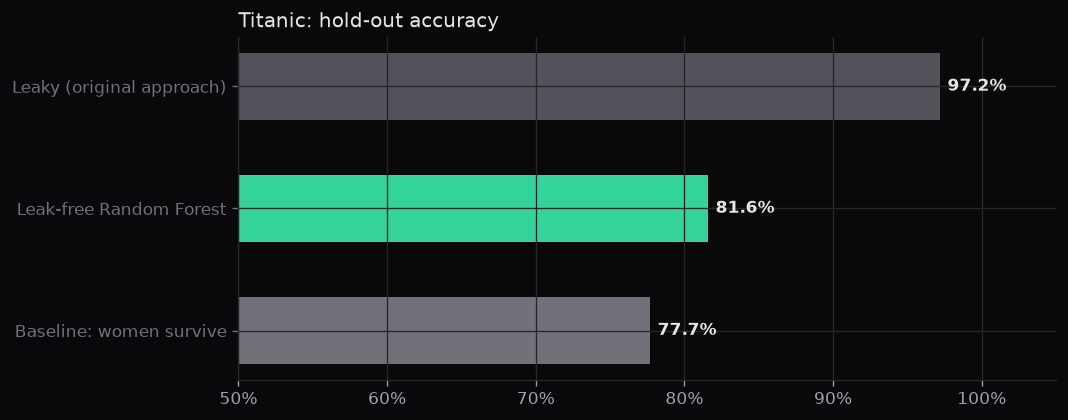

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6), dpi=120)
colores = ['#52525b', '#34d399', '#71717a']
ax.barh(tabla.index[::-1], tabla.iloc[::-1, 0], color=colores[::-1], height=0.55)
for i, v in enumerate(tabla.iloc[::-1, 0]):
    ax.text(v + 0.005, i, f'{v:.1%}', va='center', color='#e4e4e7', fontweight='bold')
ax.set_xlim(0.5, 1.05); ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}')
ax.set_title('Titanic: hold-out accuracy', loc='left', color='#e4e4e7')
plt.tight_layout()
plt.savefig('../assets/leak_comparison.png')
plt.show()

## Takeaways (computed from the results above)

In [6]:
print(f'1. Leaky setup: {acc_fuga:.1%} on the hold-out. Without the leak: {acc_limpio:.1%}.')
print('   Most of the original 98.9% came from the leak, not from the model.')
dif = acc_limpio - acc_genero
veredicto = 'beats' if dif > 0 else 'does not beat'
print(f'2. The leak-free forest {veredicto} the women-survive baseline ({acc_genero:.1%}) by {dif * 100:+.1f} points '
      f'on {len(y_te)} passengers. CV accuracy on the training split: {acc_cv:.1%}.')
print('3. Features built from the target (group rates, target encoding) must be fit inside the training fold,')
print('   and on the training rows they must leave each row out of its own rate.')

1. Leaky setup: 97.2% on the hold-out. Without the leak: 81.6%.
   Most of the original 98.9% came from the leak, not from the model.
2. The leak-free forest beats the women-survive baseline (77.7%) by +3.9 points on 179 passengers. CV accuracy on the training split: 84.8%.
3. Features built from the target (group rates, target encoding) must be fit inside the training fold,
   and on the training rows they must leave each row out of its own rate.
